[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tonyscan6003/CE5021_group01_AY2627/blob/main/Assign01/Assignment1.ipynb)

## Working with this notebook on GitHub & Colab
This notebook is in your group's private GitHub repository. Each student saves their own work to a personal **branch** (their own copy of the repository's files) named after their GitHub username, so group members never overwrite each other's work.

**Once, before your first save: create your branch** (on github.com)
1. Open your group repository on GitHub.
2. Click the branch button above the file list (it shows `main`), type your GitHub username and click **Create branch: *username* from main**.

**Open the notebook** (in Colab)
1. Go to [colab.research.google.com](https://colab.research.google.com) and choose *File → Open notebook → GitHub*.
2. Tick **Include private repos**. The first time, Colab asks for access to your GitHub account: allow it.
3. Select your group repository, then the branch:
   * a new assignment: branch `main`
   * continuing your own work: **your branch**
4. Click the notebook to open it.

**Save your work** (Colab does not save to GitHub automatically)
* Choose *File → Save a copy in GitHub*: select your group repository and **your branch** (not `main`), keep the file path, and write a short commit message saying what you changed.
* Save regularly. Changes not saved to GitHub are lost when you close the Colab tab.
* Plots and printed results are saved with the notebook, so save again after your final training run.

# Regularisation and Optimisation
This assignment investigates training of CNNs on CIFAR with a goal of maximising accuracy.

[CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html) is a dataset with small size (32x32) images and 50k training samples.
* It is often used as a "Hello World" type data set to setup a training pipeline. As it is relatively fast to train a network with CIFAR-10, this dataset is also widely used for running comparison or optimisation experiments. For example comparing different networks, regularisation methods or optimisers. (In pytorch the CIFAR-10 dataset is available as a [pytorch dataset](https://pytorch.org/vision/0.18/generated/torchvision.datasets.CIFAR10.html) simplifying loading the dataset.)

The starting point in this assignment is an untrained convolutional neural network.
* You will not modify the structure of the network. (We will discuss network structures in more detail later in the module).
* The network has sufficient capacity (Parameters/FLOPS) to achieve high accuracy.
* The notebook (starting configuration) will train the model without regularisation and using the SGD optimiser. From inspection of the training/validation accuracy/loss, it will be observed that the network is overfitting.
* You will improve the performance of the network using regularisation techniques (See below).
* The goal is to use one or several techniques to prevent overfitting and maximise test accuracy.

Regularisation techniques.
* [Data Augmentation using pytorch transforms](https://pytorch.org/vision/0.15/transforms.html)
* Regularisation layers such as [dropout](https://pytorch.org/docs/stable/generated/torch.nn.Dropout.html) and [batch normalisation](https://pytorch.org/docs/stable/generated/torch.nn.BatchNorm2d.html).

The learning rate also acts as a regulariser, with large learning rates having a regularising effect. You may also include a LR schedule as detailed in the [pytorch optim package](https://pytorch.org/docs/stable/optim.html). The optim package contains several implementations of LR schedules including those detailed in the papers:
* [Cyclical Learning Rates for Training Neural Networks](https://arxiv.org/pdf/1506.01186)
* [Super-Convergence: Very Fast Training of Neural
Networks Using Large Learning Rates](https://arxiv.org/pdf/1708.07120)

How to approach this Assignment.
* There are a lot things to try and possible approaches. Keep a record of what you have tried (`history.summary()` prints the settings and final accuracies of each run). Apart from recording training and test accuracy, ensure that you record the key hyperparameters, including optimiser, base learning rate, number of epochs for each run. This makes repeating experiments possible if you want to try a variation.
* Your final submitted notebook should include your best attempt showing training curves. Post your results and comments on your approach to the module forum.
* Routine code (loading data, measuring accuracy, plotting) comes from the course helper package `ce5021`, installed in the first cell. The training loop is in this notebook so you can read and change it. To see how a helper works, run `help(evaluate)` or `evaluate??` in a cell. (Do not submit a notebook with multiple approaches)

## 1. Setup

The dependencies are installed in the local virtual environment. Select that environment as the notebook kernel before running the imports.


In [6]:
import sys
print("Python environment:", sys.executable)


Python environment: /home/ciaran/Source/College/Modules/Year 2/CE5021 - Deep Learning for Computer Vision/.venv/bin/python


In [7]:
import copy
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision.transforms import v2
from torchinfo import summary
from sklearn.metrics import classification_report

from ce5021.data import cifar10_datasets, CIFAR10_CLASSES, IMAGENET_MEAN, IMAGENET_STD
from ce5021.train import get_device, evaluate, predict, History
from ce5021.plots import show_batch, show_predictions, plot_confusion_matrix


## 2. Dataset and configuration

The 50,000 CIFAR-10 training images are split into 45,000 training and 5,000 validation images. The training images are augmented using random crops with reflection padding and horizontal flips. Validation and test images are converted and normalised without augmentation.


In [8]:
config = dict(
    run_name="final_model",
    n_epochs=40,
    batch_size=128,
    validation_size=5_000,
    lr=0.01,
    momentum=0.9,
    weight_decay=0.0005,
    lr_step=30,
    lr_gamma=0.1,
    dropout=0.5,
    conv_dropout=0.15,
)


In [9]:
train_transforms = v2.Compose([
    v2.ToImage(),
    v2.RandomCrop(32, padding=4, padding_mode="reflect"),
    v2.RandomHorizontalFlip(p=0.5),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

test_transforms = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


The validation set uses the same normalisation as the training set, without random augmentation. The test set is evaluated after training.


In [10]:
batch_size = config["batch_size"]
validation_size = config["validation_size"]

train_data, test_data = cifar10_datasets(train_transforms, test_transforms)
validation_data = copy.copy(train_data)
validation_data.transform = test_transforms

indices = torch.randperm(len(train_data)).tolist()
validation_indices = indices[:validation_size]
train_indices = indices[validation_size:]

train_loader = DataLoader(
    Subset(train_data, train_indices), batch_size=batch_size, shuffle=True,
    num_workers=2,
)
val_loader = DataLoader(
    Subset(validation_data, validation_indices), batch_size=batch_size,
    shuffle=False, num_workers=2,
)
train_eval_loader = DataLoader(
    Subset(validation_data, train_indices), batch_size=batch_size,
    shuffle=False, num_workers=2,
)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)

print(f"Training images:   {len(train_loader.dataset):,}")
print(f"Validation images: {len(val_loader.dataset):,}")
print(f"Test images:       {len(test_loader.dataset):,} (held out)")
images, labels = next(iter(train_loader))
print("One batch of images [N, C, H, W]:", tuple(images.shape))


CIFAR-10 loaded (from the Hugging Face copy of the dataset)
Training images:   45,000
Validation images: 5,000
Test images:       10,000 (held out)
One batch of images [N, C, H, W]: (128, 3, 32, 32)


Example training images, after the transforms (any augmentation you add is visible here).

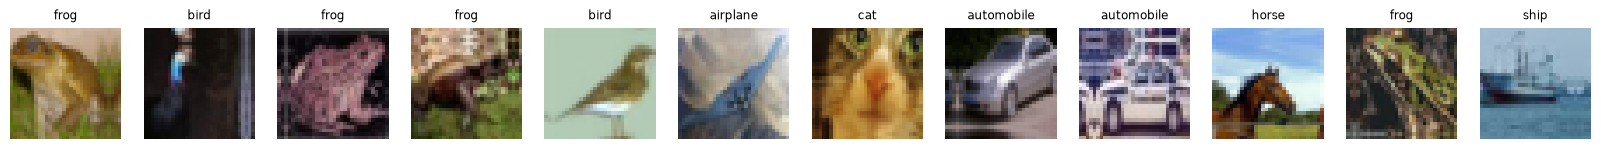

In [11]:
show_batch(train_loader, CIFAR10_CLASSES)

## 3. CNN Model

The CNN uses batch normalisation after each convolution and dropout before pooling and after the first dense layer. The final layer produces logits for the ten CIFAR-10 classes.


In [12]:
device = get_device()

Using cuda device


In [13]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.simple_cnn = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding='same'),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 64, 3, padding='same'),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Dropout2d(config["conv_dropout"]),
            nn.MaxPool2d(2),                      # 32x32 -> 16x16
            nn.Conv2d(64, 64, 3, padding='same'),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding='same'),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Dropout2d(config["conv_dropout"]),
            nn.MaxPool2d(2),                      # 16x16 -> 8x8
            nn.Conv2d(64, 128, 3, padding='same'),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 256, 3, padding='same'),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.Conv2d(256, 256, 3, padding='same'),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.Dropout2d(config["conv_dropout"]),
            nn.MaxPool2d(2),                      # 8x8 -> 4x4
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 512),
            nn.ReLU(),
            nn.Dropout(config["dropout"]),
            nn.Linear(512, 10),                   # one output (logit) per class
        )

    def forward(self, x):
        logits = self.simple_cnn(x)
        return logits

In [14]:
# Layer-by-layer summary: output shapes and number of parameters
summary(NeuralNetwork(), input_size=(batch_size, 3, 32, 32))

Layer (type:depth-idx)                   Output Shape              Param #
NeuralNetwork                            [128, 10]                 --
├─Sequential: 1-1                        [128, 10]                 --
│    └─Conv2d: 2-1                       [128, 32, 32, 32]         896
│    └─BatchNorm2d: 2-2                  [128, 32, 32, 32]         64
│    └─ReLU: 2-3                         [128, 32, 32, 32]         --
│    └─Conv2d: 2-4                       [128, 64, 32, 32]         18,496
│    └─BatchNorm2d: 2-5                  [128, 64, 32, 32]         128
│    └─ReLU: 2-6                         [128, 64, 32, 32]         --
│    └─Dropout2d: 2-7                    [128, 64, 32, 32]         --
│    └─MaxPool2d: 2-8                    [128, 64, 16, 16]         --
│    └─Conv2d: 2-9                       [128, 64, 16, 16]         36,928
│    └─BatchNorm2d: 2-10                 [128, 64, 16, 16]         128
│    └─ReLU: 2-11                        [128, 64, 16, 16]         --
│   

## 4. Optimisation and Training

The model is trained with cross entropy loss and SGD with momentum and weight decay. The learning rate decreases after epoch 30. The checkpoint with the highest validation accuracy is restored after training.


In [15]:
def train_one_epoch(model, loader, loss_fn, optimizer, device):
    model.train()
    total_loss, correct, seen = 0.0, 0, 0

    for inputs, labels in loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = loss_fn(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(labels)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        seen += len(labels)

    return total_loss / seen, 100 * correct / seen


Optional: run the next cell **before** training to watch progress live in TensorBoard. TensorBoard is not saved with the notebook, so it will not be visible on GitHub; the plots after training are. (On a local runtime, if the TensorBoard panel stays blank, open [http://localhost:6006](http://localhost:6006) in a new browser tab instead.)

In [16]:
%load_ext tensorboard
%tensorboard --logdir runs

Reusing TensorBoard on port 6006 (pid 47549), started 2 days, 14:22:22 ago. (Use '!kill 47549' to kill it.)

### 4.1 Training settings


In [17]:
print(config)


{'run_name': 'final_model', 'n_epochs': 40, 'batch_size': 128, 'validation_size': 5000, 'lr': 0.01, 'momentum': 0.9, 'weight_decay': 0.0005, 'lr_step': 30, 'lr_gamma': 0.1, 'dropout': 0.5, 'conv_dropout': 0.15}


### 4.2 Training


In [18]:
model = NeuralNetwork().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(
    model.parameters(), lr=config["lr"], momentum=config["momentum"],
    weight_decay=config["weight_decay"],
)
scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer, step_size=config["lr_step"], gamma=config["lr_gamma"],
)
history = History(config["run_name"], config=config)
best_weights = None

for epoch in range(config["n_epochs"]):
    train_loss, train_acc = train_one_epoch(model, train_loader, loss_fn, optimizer, device)
    val_loss, val_acc = evaluate(model, val_loader, loss_fn, device)
    history.log(epoch, train_loss, train_acc, val_loss, val_acc,
                lr=optimizer.param_groups[0]["lr"])

    if history.is_best():
        best_weights = copy.deepcopy(model.state_dict())
    scheduler.step()

if best_weights is not None:
    model.load_state_dict(best_weights)
    print(f"Restored best validation model from epoch {history.best_index() + 1}.")
print("Finished training")


Epoch   1 | train loss 1.6564  acc  38.5% | val loss 1.2542  acc  52.4%  lr 1.00e-02  *best
Epoch   2 | train loss 1.3474  acc  51.4% | val loss 1.0783  acc  60.0%  lr 1.00e-02  *best
Epoch   3 | train loss 1.1869  acc  57.7% | val loss 0.9126  acc  68.0%  lr 1.00e-02  *best
Epoch   4 | train loss 1.0735  acc  62.2% | val loss 0.7963  acc  71.1%  lr 1.00e-02  *best
Epoch   5 | train loss 0.9899  acc  65.4% | val loss 0.7745  acc  72.9%  lr 1.00e-02  *best
Epoch   6 | train loss 0.9156  acc  67.6% | val loss 0.7189  acc  73.4%  lr 1.00e-02  *best
Epoch   7 | train loss 0.8678  acc  69.9% | val loss 0.6597  acc  76.6%  lr 1.00e-02  *best
Epoch   8 | train loss 0.8074  acc  72.1% | val loss 0.5822  acc  80.0%  lr 1.00e-02  *best
Epoch   9 | train loss 0.7690  acc  73.6% | val loss 0.6151  acc  78.2%  lr 1.00e-02
Epoch  10 | train loss 0.7296  acc  75.0% | val loss 0.5547  acc  80.8%  lr 1.00e-02  *best
Epoch  11 | train loss 0.6930  acc  76.3% | val loss 0.4803  acc  83.6%  lr 1.00e-02  *

### 4.3 Training curves


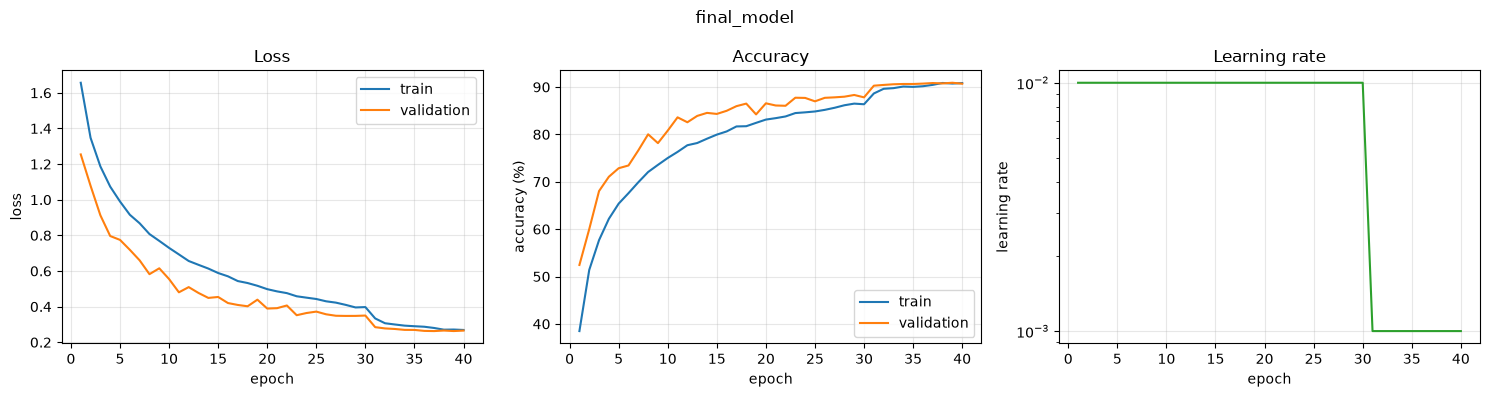

run             : final_model
n_epochs        : 40
batch_size      : 128
validation_size : 5000
lr              : 0.01
momentum        : 0.9
weight_decay    : 0.0005
lr_step         : 30
lr_gamma        : 0.1
dropout         : 0.5
conv_dropout    : 0.15
epochs trained  : 40
final train acc : 90.8
final val acc   : 90.7
best val acc    : 90.9
best epoch      : 39


In [19]:
history.plot()
history.summary();

## 5. Final evaluation

Training accuracy is measured on the unaugmented training subset in evaluation mode, using the same preprocessing as the test set. The best validation checkpoint is used for both measurements.


In [20]:
train_eval_loss, train_eval_acc = evaluate(model, train_eval_loader, loss_fn, device)
test_loss, test_acc = evaluate(model, test_loader, loss_fn, device)
print(f"Training accuracy: {train_eval_acc:.2f}%")
print(f"Test accuracy:     {test_acc:.2f}%")
print(f"Train/test gap:    {train_eval_acc - test_acc:.2f} percentage points")

y_true, y_pred = predict(model, test_loader, device)
print(classification_report(y_true, y_pred, target_names=CIFAR10_CLASSES))


Training accuracy: 95.15%
Test accuracy:     90.35%
Train/test gap:    4.80 percentage points
              precision    recall  f1-score   support

    airplane       0.91      0.92      0.92      1000
  automobile       0.96      0.95      0.95      1000
        bird       0.91      0.84      0.88      1000
         cat       0.81      0.78      0.79      1000
        deer       0.89      0.92      0.90      1000
         dog       0.86      0.83      0.84      1000
        frog       0.90      0.96      0.93      1000
       horse       0.93      0.94      0.93      1000
        ship       0.94      0.95      0.95      1000
       truck       0.92      0.95      0.93      1000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



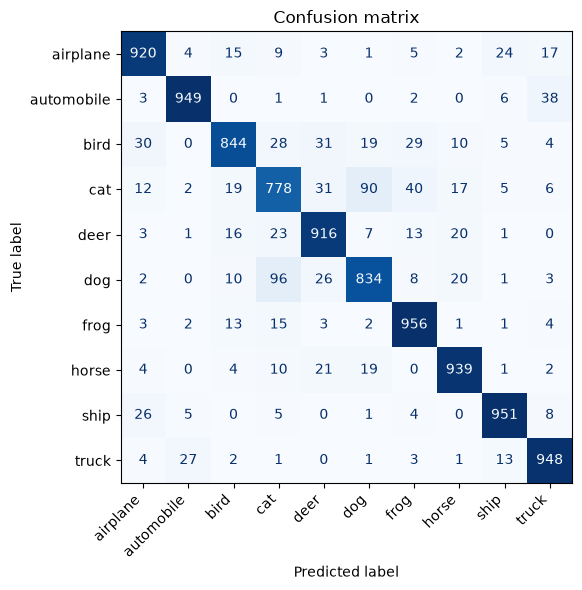

In [21]:
plot_confusion_matrix(y_true, y_pred, CIFAR10_CLASSES)

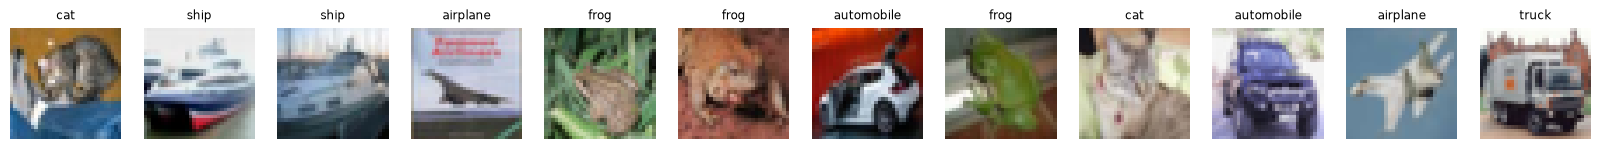

In [22]:
show_predictions(model, test_loader, device, CIFAR10_CLASSES)

## Results

The best validation checkpoint was at epoch 39. It achieved 90.35% test accuracy and 95.15% training accuracy, a gap of 4.80 percentage points. Training accuracy was measured separately on the training subset without augmentation and in evaluation mode, using the same preprocessing as the test set.

The CIFAR-10 test set was inspected during earlier experiments, so the final test result should be interpreted with that in mind.
